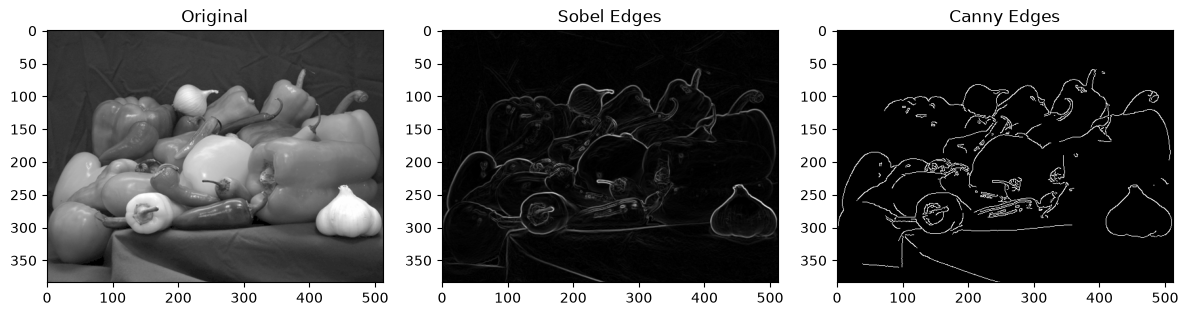

In [1]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('peppers.png', cv2.IMREAD_GRAYSCALE)

sobelx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

sobel_combined = cv2.magnitude(sobelx, sobely)

canny_edges = cv2.Canny(img, 100, 200)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1), plt.imshow(img, cmap='gray'), plt.title('Original')
plt.subplot(1, 3, 2), plt.imshow(sobel_combined, cmap='gray'), plt.title('Sobel Edges')
plt.subplot(1, 3, 3), plt.imshow(canny_edges, cmap='gray'), plt.title('Canny Edges')
plt.tight_layout()
plt.show()


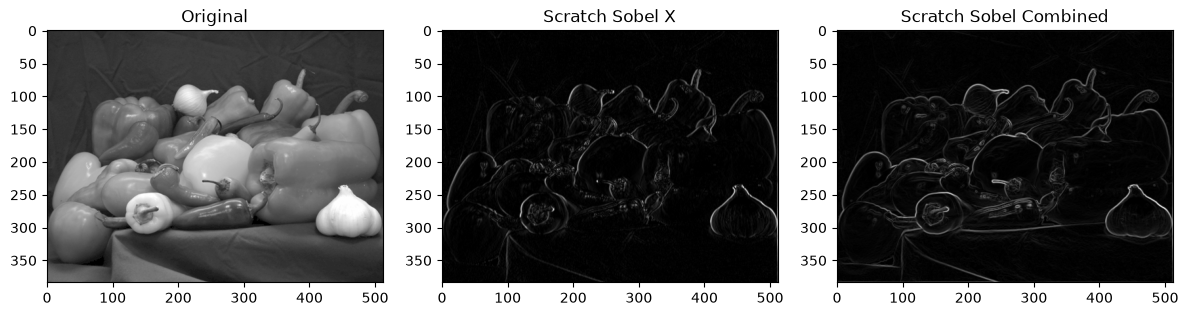

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Load image
img = cv2.imread('peppers.png', cv2.IMREAD_GRAYSCALE)
h, w = img.shape

# Define standard 3x3 Sobel kernels
Gx = np.array([[-1, 0, 1], 
               [-2, 0, 2], 
               [-1, 0, 1]], dtype=np.float64)

Gy = np.array([[-1, -2, -1], 
               [ 0,  0,  0], 
               [ 1,  2,  1]], dtype=np.float64)

# Pad image by 1 pixel to handle borders
padded = np.pad(img, 1, mode='constant', constant_values=0)

# Initialize output arrays
sobel_x = np.zeros_like(img, dtype=np.float64)
sobel_y = np.zeros_like(img, dtype=np.float64)
sobel_combined = np.zeros_like(img, dtype=np.float64)

# Apply convolution via loops
for i in range(h):
    for j in range(w):
        # Extract the local 3x3 neighborhood
        region = padded[i:i+3, j:j+3]
        
        # Calculate horizontal and vertical gradients
        val_x = np.sum(region * Gx)
        val_y = np.sum(region * Gy)
        
        sobel_x[i, j] = val_x
        sobel_y[i, j] = val_y
        
        # Calculate magnitude (combined edges)
        sobel_combined[i, j] = np.sqrt(val_x**2 + val_y**2)

# Plot results
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1), plt.imshow(img, cmap='gray'), plt.title('Original')
plt.subplot(1, 3, 2), plt.imshow(np.abs(sobel_x), cmap='gray'), plt.title('Scratch Sobel X')
plt.subplot(1, 3, 3), plt.imshow(sobel_combined, cmap='gray'), plt.title('Scratch Sobel Combined')
plt.tight_layout()
plt.show()
